# 01 · Ablations — temporal blocking

**Question:** Under a *temporally* blocked curriculum (one category after the other, no cue), does the ISC model prefer blocked or interleaved training?
**Dissertation:** §2.3 (Exp 2.3.1), Fig 2.5
**Dates:** 2026-02-06 – 2026-05-07 (commits `32e753f`, `524b5e6`, `27b3b85`)
**Inputs:** `data/01_ablations/hebbian_simulation_n{10,40}.csv` (written by `isc_ablations.hebbian_model.experiment.run_hebbian_baseline`, Feb 2026 version)
**Outputs:** inline only. Two outputs were saved by hand: cell "ISC: Temporal Blocked vs Interleaved" → `figures/01_ablations/isc_temporal_blocked_vs_interleaved.png` (Fig 2.5), and the 40-epoch Hebbian-vs-ISC plot → `figures/01_ablations/hebbian_vs_isc_temporal_40ep.png`.

Formerly `new_directions.ipynb` §2; its easy/hard section now lives in `experiments/02_easy_hard/easy_hard_curriculum.ipynb`.

> Cells were run out of order during research; each section says which cells produce which files.
> Re-running is **not** a no-op: most experiment code loads cached checkpoints from `models/` and silently retrains (and overwrites outputs) when a checkpoint is missing.

In [ ]:
# Run from the repo root so data/, models/ and figures/ paths resolve, and isc_ablations is importable.
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'isc_ablations').is_dir())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

## 1. Modelling continual learning in humans with Hebbian context gating and exponentially decaying task signals

We next replicate the context gating from this paper, implementing slow neurons.

> **Date:** 2026-02-06 (`32e753f`, `524b5e6`); ISC-only plot added 2026-05-07 (`27b3b85`) · **Status:** last cell = final (Fig 2.5); the Hebbian bars are superseded  
> **Question:** Blocked vs interleaved accuracy for the ISC model, and a first Hebbian (context-gating, Flesch et al. 2023) variant, after 10 and 40 epochs.  
> **Setup:** `run_hebbian_baseline(num_epochs ∈ {10, 40}, num_models=10)` → `data/01_ablations/hebbian_simulation_n{10,40}.csv`; ISC-baseline cache `models/01_ablations/isc_{interl,blockd}-N.torch` (not tracked, so a rerun retrains). The Hebbian rows came from the pre-Oja `HebbianModel` (removed in `035ae04`); the final Hebbian comparison is in `03_oja/oja_verification.ipynb` §3.  
> **Result:** Dissertation §2.3: the model performs better on interleaved training (Fig 2.5). ⚠ The error bars here are standard deviations; Exp 2.3.1 in the dissertation says standard error.  
> **Output:** inline; see header for the hand-saved PNGs

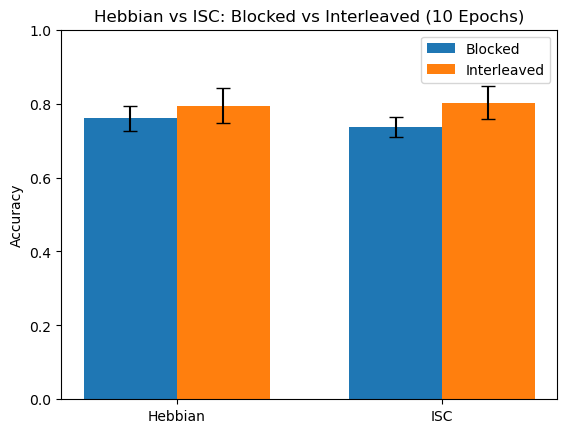

In [7]:
df = pd.read_csv('data/01_ablations/hebbian_simulation_n10.csv')

model_means = df.groupby(['architecture', 'condition', 'model'])['acc'].mean()
stats = model_means.groupby(['architecture', 'condition']).agg(['mean', 'std'])

def get_mean_std(arch, cond):
    row = stats.loc[(arch, cond)]
    return row['mean'], row['std']

hebbian_blocked_mean,     hebbian_blocked_std     = get_mean_std("Hebbian", "blocked")
hebbian_interleaved_mean, hebbian_interleaved_std = get_mean_std("Hebbian", "interleaved")
isc_blocked_mean,         isc_blocked_std         = get_mean_std("ISC", "blocked")
isc_interleaved_mean,     isc_interleaved_std     = get_mean_std("ISC", "interleaved")

models = ["Hebbian", "ISC"]
blocked         = [hebbian_blocked_mean,      isc_blocked_mean]
blocked_err     = [hebbian_blocked_std,       isc_blocked_std]
interleaved     = [hebbian_interleaved_mean,  isc_interleaved_mean]
interleaved_err = [hebbian_interleaved_std,   isc_interleaved_std]

x = np.arange(len(models))
width = 0.35

plt.figure()
plt.bar(x - width/2, blocked,     width, label="Blocked",     yerr=blocked_err,     capsize=5)
plt.bar(x + width/2, interleaved, width, label="Interleaved", yerr=interleaved_err, capsize=5)

plt.xticks(x, models)
plt.ylabel("Accuracy")
plt.title("Hebbian vs ISC: Blocked vs Interleaved (10 Epochs)")
plt.legend()
plt.ylim(0, 1)
plt.show()

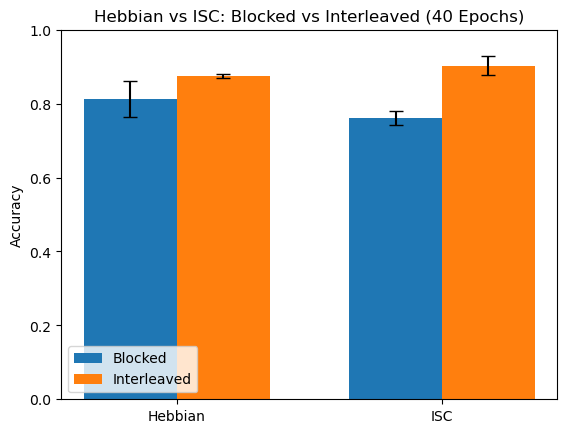

In [6]:
df = pd.read_csv('data/01_ablations/hebbian_simulation_n40.csv')

model_means = df.groupby(['architecture', 'condition', 'model'])['acc'].mean()
stats = model_means.groupby(['architecture', 'condition']).agg(['mean', 'std'])

def get_mean_std(arch, cond):
    row = stats.loc[(arch, cond)]
    return row['mean'], row['std']

hebbian_blocked_mean,     hebbian_blocked_std     = get_mean_std("Hebbian", "blocked")
hebbian_interleaved_mean, hebbian_interleaved_std = get_mean_std("Hebbian", "interleaved")
isc_blocked_mean,         isc_blocked_std         = get_mean_std("ISC", "blocked")
isc_interleaved_mean,     isc_interleaved_std     = get_mean_std("ISC", "interleaved")

models = ["Hebbian", "ISC"]
blocked         = [hebbian_blocked_mean,      isc_blocked_mean]
blocked_err     = [hebbian_blocked_std,       isc_blocked_std]
interleaved     = [hebbian_interleaved_mean,  isc_interleaved_mean]
interleaved_err = [hebbian_interleaved_std,   isc_interleaved_std]

x = np.arange(len(models))
width = 0.35

plt.figure()
plt.bar(x - width/2, blocked,     width, label="Blocked",     yerr=blocked_err,     capsize=5)
plt.bar(x + width/2, interleaved, width, label="Interleaved", yerr=interleaved_err, capsize=5)

plt.xticks(x, models)
plt.ylabel("Accuracy")
plt.title("Hebbian vs ISC: Blocked vs Interleaved (40 Epochs)")
plt.legend()
plt.ylim(0, 1)
plt.show()

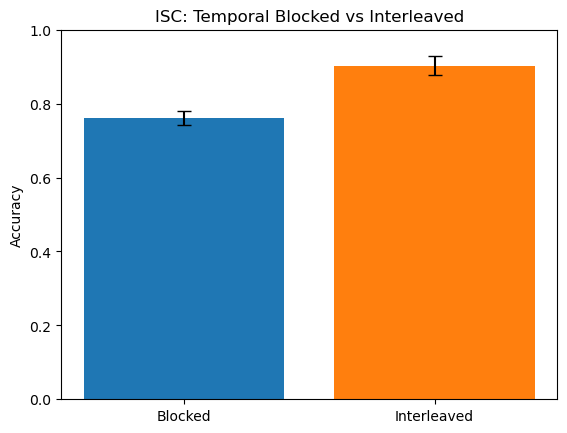

In [5]:
df = pd.read_csv('data/01_ablations/hebbian_simulation_n40.csv')

isc_data = df[df['architecture'] == 'ISC']
model_means = isc_data.groupby(['condition', 'model'])['acc'].mean()
stats = model_means.groupby('condition').agg(['mean', 'std'])

conditions = ['blocked', 'interleaved']
labels = ['Blocked', 'Interleaved']
means = [stats.loc[condition, 'mean'] for condition in conditions]
errs = [stats.loc[condition, 'std'] for condition in conditions]

x = np.arange(len(labels))

plt.figure()
plt.bar(x, means, yerr=errs, capsize=5, color=['#1f77b4', '#ff7f0e'])
plt.xticks(x, labels)
plt.ylabel('Accuracy')
plt.title('ISC: Temporal Blocked vs Interleaved')
plt.ylim(0, 1)
plt.show()